In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [2]:
from pathlib import Path

train_candidates = list(Path("/kaggle/input").rglob("train.csv"))
test_candidates = list(Path("/kaggle/input").rglob("test.csv"))

print("Train files found:", train_candidates)
print("Test files found:", test_candidates)

train_path = train_candidates[0]
test_path = test_candidates[0]

print("Train path:", train_path)
print("Test path:", test_path)

Train files found: [PosixPath('/kaggle/input/competitions/house-prices-advanced-regression-techniques/train.csv')]
Test files found: [PosixPath('/kaggle/input/competitions/house-prices-advanced-regression-techniques/test.csv')]
Train path: /kaggle/input/competitions/house-prices-advanced-regression-techniques/train.csv
Test path: /kaggle/input/competitions/house-prices-advanced-regression-techniques/test.csv


In [3]:
train = pd.read_csv(train_path)
test = pd.read_csv(test_path)

print("Train shape:", train.shape)
print("Test shape:", test.shape)

Train shape: (1460, 81)
Test shape: (1459, 80)


In [4]:
train.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [5]:
print("Train rows:", train.shape[0])
print("Train columns:", train.shape[1])

print("Test rows:", test.shape[0])
print("Test columns:", test.shape[1])

Train rows: 1460
Train columns: 81
Test rows: 1459
Test columns: 80


In [6]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [7]:
missing = train.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

missing.head(30)

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64

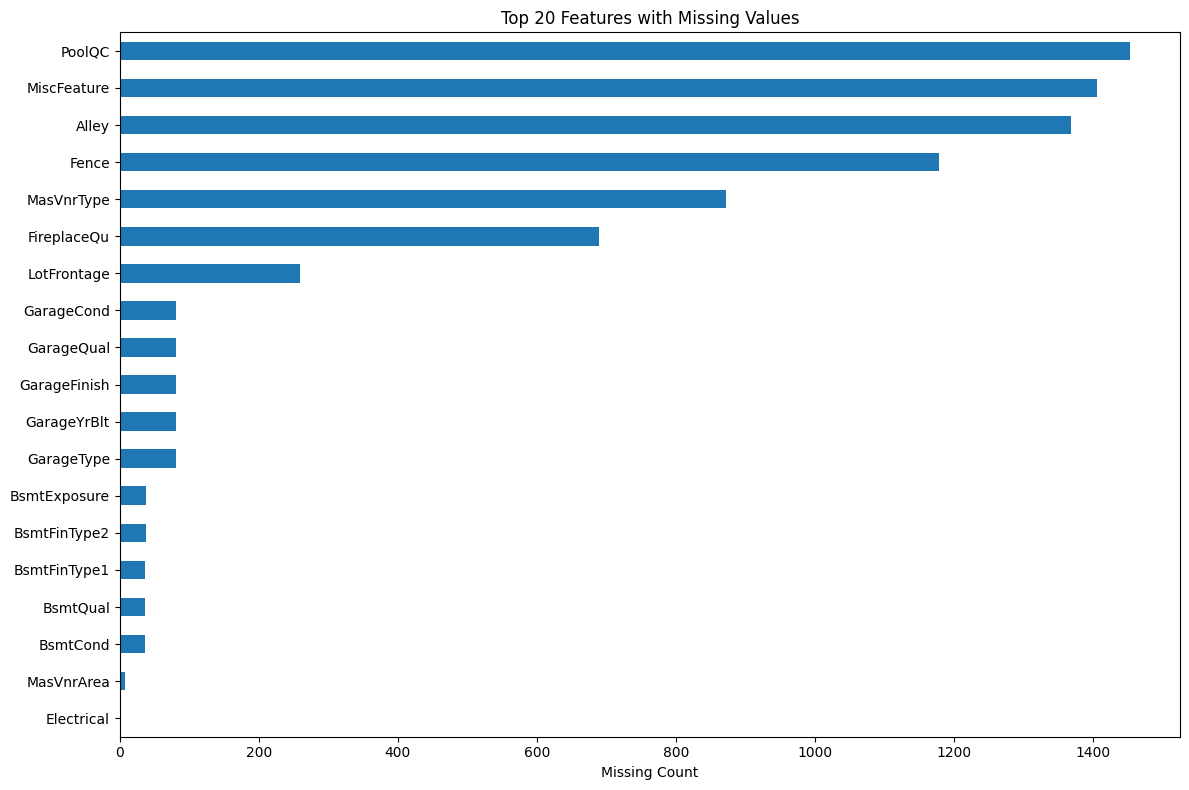

In [8]:
plt.figure(figsize=(12, 8))

missing.head(20).sort_values().plot(kind="barh")

plt.title("Top 20 Features with Missing Values")
plt.xlabel("Missing Count")
plt.tight_layout()

plt.show()

In [9]:
train["SalePrice"].describe()

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

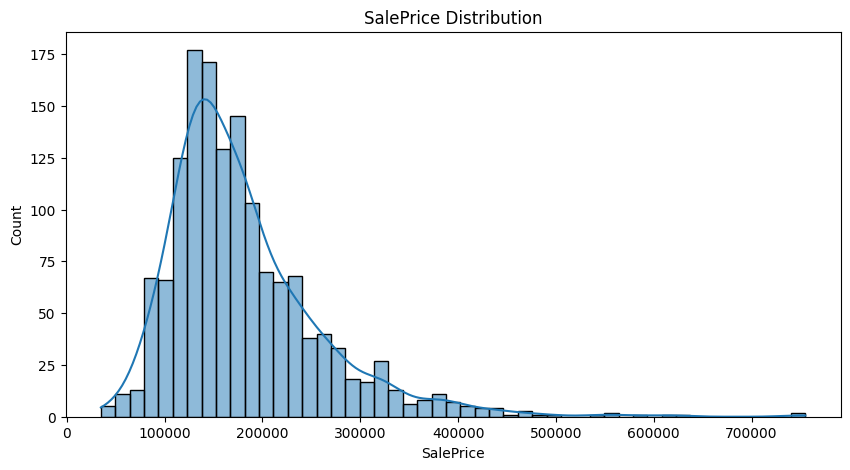

In [10]:
plt.figure(figsize=(10, 5))

sns.histplot(train["SalePrice"], kde=True)

plt.title("SalePrice Distribution")
plt.xlabel("SalePrice")
plt.show()

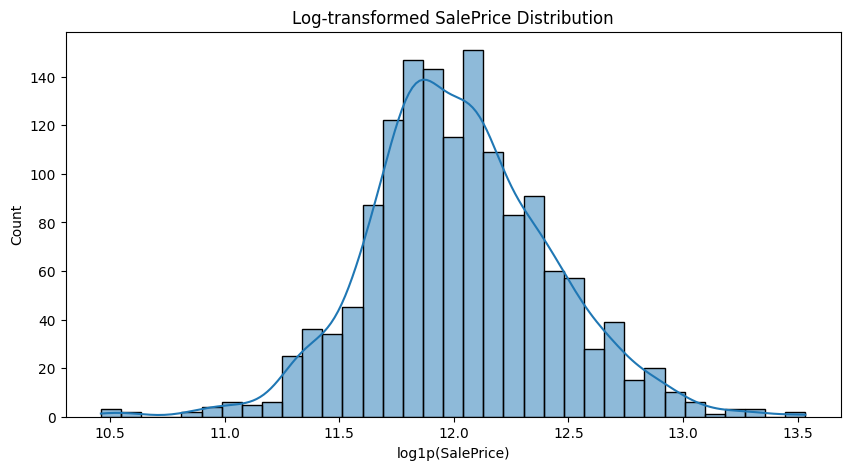

In [11]:
train["LogSalePrice"] = np.log1p(train["SalePrice"])

plt.figure(figsize=(10, 5))

sns.histplot(train["LogSalePrice"], kde=True)

plt.title("Log-transformed SalePrice Distribution")
plt.xlabel("log1p(SalePrice)")
plt.show()

In [12]:
numeric_cols = train.select_dtypes(include=np.number).columns

print("Number of numerical columns:", len(numeric_cols))

Number of numerical columns: 39


In [13]:
corr = train[numeric_cols].corr()["SalePrice"].sort_values(ascending=False)

corr.head(15)

SalePrice       1.000000
LogSalePrice    0.948374
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
YearRemodAdd    0.507101
GarageYrBlt     0.486362
MasVnrArea      0.477493
Fireplaces      0.466929
Name: SalePrice, dtype: float64

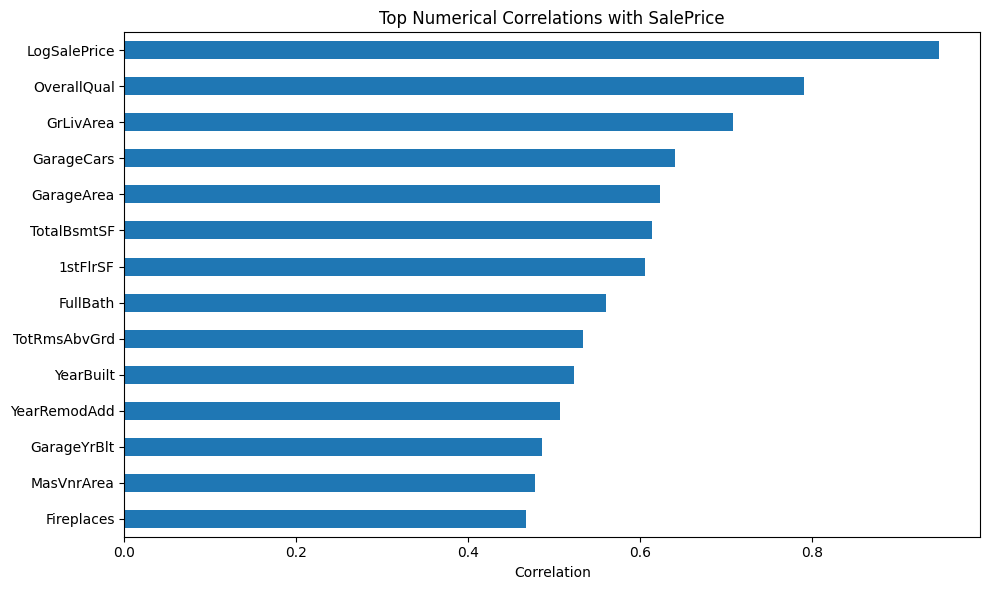

In [14]:
plt.figure(figsize=(10, 6))

corr.head(15).drop("SalePrice").sort_values().plot(kind="barh")

plt.title("Top Numerical Correlations with SalePrice")
plt.xlabel("Correlation")
plt.tight_layout()

plt.show()

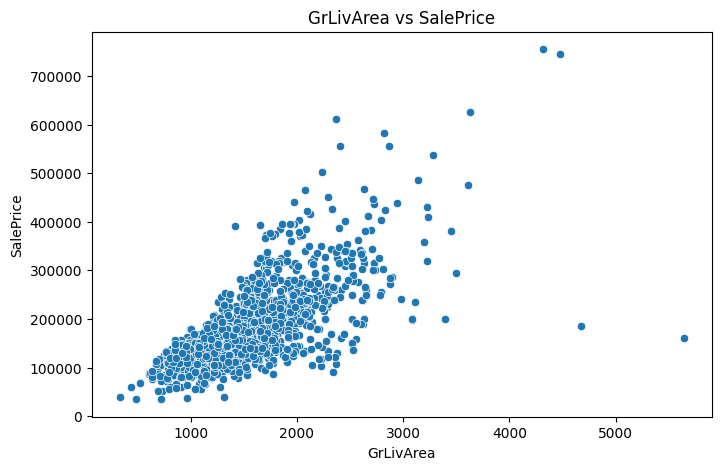

In [15]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=train,
    x="GrLivArea",
    y="SalePrice"
)

plt.title("GrLivArea vs SalePrice")
plt.show()

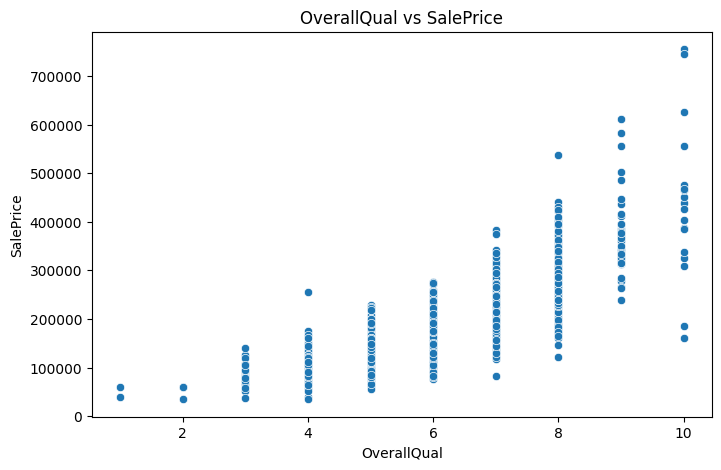

In [16]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=train,
    x="OverallQual",
    y="SalePrice"
)

plt.title("OverallQual vs SalePrice")
plt.show()

In [17]:
categorical_cols = train.select_dtypes(include="object").columns

print("Number of categorical columns:", len(categorical_cols))

Number of categorical columns: 43


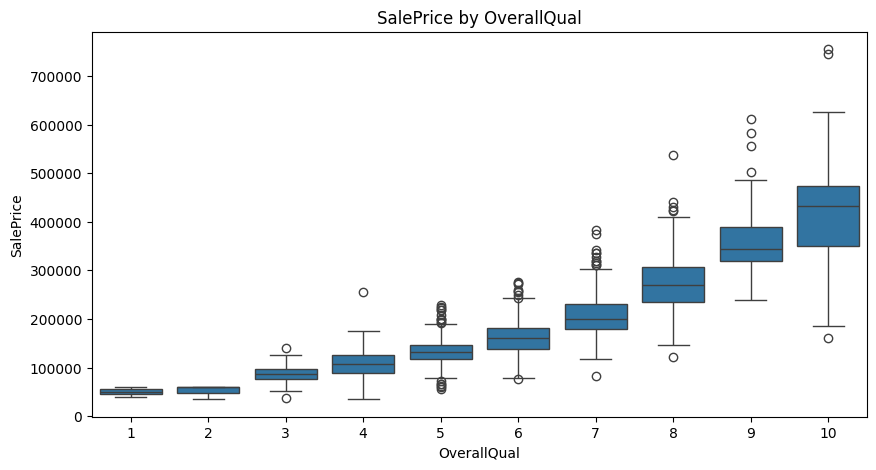

In [18]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=train,
    x="OverallQual",
    y="SalePrice"
)

plt.title("SalePrice by OverallQual")
plt.show()

## EDA Observations

1. The target variable SalePrice is right-skewed.
2. Log transformation produces a more symmetric target distribution.
3. Several features contain missing values and require preprocessing.
4. OverallQual has a strong relationship with SalePrice.
5. Living area and total residential size show meaningful relationships with house prices.
6. Some observations may behave as potential outliers and should be considered during modeling.